# Chapter 2-Part 3  - Handling Missing Data in Python
####[**Instructor**: Dr. Heyfa Ammar]

## 🎓 Mission: Rescue the Gradebook


---

**The scenario:**

It's 4:12 PM. Final grades for CS316 are due to the Registrar's Office at 5:00 PM sharp.
Your instructor just forwarded you — the course TA — the gradebook export from the LMS, with one line in the email:

> *"The export glitched again. Some cells are blank. Can you clean this up before 5? I trust your judgment — just don't invent grades that aren't real. 🙏"*

You open the CSV. It looks fine at first glance... until you scroll. Missing majors. Missing project scores. Missing names. One column is *riddled* with gaps.

You have 48 minutes. This notebook is your toolkit.

**By the end of this notebook you will be able to:**
- Detect and quantify missing values in a `pandas` DataFrame (`isnull`, `isnull().sum()`)
- Explain *why* missing data matters and visualize where it hides
- Decide, column by column, whether to **drop** or **fill** missing values — and defend that choice
- Apply `dropna()` (with `subset`, `axis`, `thresh`) and `fillna()` (constant, mean, median, `ffill`/`bfill`)
- Build a repeatable cleaning pipeline and verify the result

Let's save the gradebook. ⏱️

## 🧰 Step 0 — Set up your toolkit

Every rescue mission starts with the right tools. Run the cell below to import the libraries
we'll use and set a couple of display options so DataFrames are easy to read.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Seaborn is a Python data-visualization library built on top of matplotlib.
import seaborn as sns

pd.set_option("display.max_columns", None) #None here means "no limit" — it tells pandas not to truncate the number of columns shown, no matter how many there are.
                                           #Why this setting exists: by default, pandas caps how many columns it will print (the default is 20). If a DataFrame has more columns than that, pandas hides the middle ones and shows ... instead

pd.set_option("display.width", 120) #Controls how many characters wide pandas will print before wrapping a DataFrame to a new line.
                                    #Setting it to 120 characters gives pandas enough room to print rows on one line instead of splitting them

sns.set_style("whitegrid") #A seaborn theme setting that applies to all matplotlib/seaborn plots made afterward in the notebook.
                           #"whitegrid" gives every chart a white background with light grey horizontal + vertical gridlines

print("Toolkit loaded. pandas version:", pd.__version__)

Toolkit loaded. pandas version: 2.2.3


## 📥 Step 1 — Open the damaged export

Here's the gradebook exactly as it landed in your inbox: `student_id`, `name`, two major
assessment scores (`major01`, `major02`), a `project` score, and the `final` exam score — all
out of 20.

(In a real course you'd read this with `pd.read_csv("gradebook.csv")`; here we build the same
DataFrame in code so the notebook runs anywhere, glitches and all.)

In [ ]:
# manually entered data that hasnt been saved
data = {
    "student_id": [900000001, 900000002, 900000003, 900000004, 900000005,
                    900000006, 900000007, 900000008, 900000009, 900000010,
                    900000011, 900000012, 900000013, 900000014, 900000015,
                    900000016, 900000017, 900000018, 900000019, 900000020],
    "name": ["Student 05", np.nan, "Student 06", "Student 02", "Student 11",
              np.nan, "Student 03", "Student 12", "Student 07", np.nan,
              "Student 01", np.nan, "Student 08", "Student 15", "Student 04",
              "Student 09", "Student 13", np.nan, "Student 14", "Student 10"],
    "major01": [15.25, 15.22, 13.25, 5.91, 16.00,
                 10.31, 15.00, 16.00, 10.00, 10.00,
                 10.56, 19.00, 20.00, 10.00, 14.75,
                 17.20, 12.10, 9.80, 16.60, 13.40],
    "major02": [14.00, 10.75, np.nan, 1.25, np.nan,
                 12.45, np.nan, 12.63, 6.38, 7.50,
                 12.00, 17.25, 18.88, np.nan, 11.90,
                 np.nan, 8.75, 10.20, np.nan, 12.85],
    "project": [18.000, 14.670, 16.250, 5.000, 6.670,
                 15.758, np.nan, 16.670, np.nan, 11.670,
                 11.330, 18.000, 18.670, np.nan, 13.400,
                 15.900, np.nan, 9.100, 14.200, np.nan],
    "final": [17.0, 27.0 / 2, np.nan, 7.0, np.nan,
               16.5, np.nan, 23.0 / 1.5, 8.0, 15.0,
               13.3, np.nan, 18.5, 3.0, 14.0,
               16.8, 10.5, np.nan, 15.5, 12.0],
}

df = pd.DataFrame(data) # convert the dataset into a dataframe
print("Shape:", df.shape) # outputs the total of rows and columns respectively - returns (row, column)
df.head(10)

Shape: (20, 6)


,student_id,name,major01,major02,project,final
0,900000001,Student 05,15.25,14.00,18.000,17.000000
1,900000002,NaN,15.22,10.75,14.670,13.500000
2,900000003,Student 06,13.25,NaN,16.250,NaN
3,900000004,Student 02,5.91,1.25,5.000,7.000000
4,900000005,Student 11,16.00,NaN,6.670,NaN
5,900000006,NaN,10.31,12.45,15.758,16.500000
6,900000007,Student 03,15.00,NaN,NaN,NaN
7,900000008,Student 12,16.00,12.63,16.670,15.333333
8,900000009,Student 07,10.00,6.38,NaN,8.000000
9,900000010,NaN,10.00,7.50,11.670,15.000000


In [ ]:
# A quick structural check — dtypes and non-null counts per column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   student_id  20 non-null     int64  
 1   name        15 non-null     object 
 2   major01     20 non-null     float64
 3   major02     14 non-null     float64
 4   project     15 non-null     float64
 5   final       15 non-null     float64
dtypes: float64(4), int64(1), object(1)
memory usage: 1.1+ KB


## 🔍 Step 2 — Assess the damage

Before fixing anything, you need to know exactly what's missing and how much. `pandas`
represents a missing value as `NaN` ("Not a Number"), and `.isnull()` (an alias of
`.isna()`) gives you a same-shaped DataFrame of `True`/`False` flags.

In [ ]:
# .isnull() flags every missing cell
df.isnull().head(6) # gives the state of each value and returns a boolean - false indicates that the entry is not missing while true indicates it is missing

,student_id,name,major01,major02,project,final
0,False,False,False,False,False,False
1,False,True,False,False,False,False
2,False,False,False,True,False,True
3,False,False,False,False,False,False
4,False,False,False,True,False,True
5,False,True,False,False,False,False


That's useful for a spot check, but with 20 rows nobody wants to scan a wall of
`True`/`False`. Sum it up instead — `True` behaves like `1`, so `.sum()` on a boolean
DataFrame counts missing values per column.

In [ ]:
missing_counts = df.isnull().sum() # counts total number of missing value per column/feature
missing_pct = (df.isnull().sum() / len(df) * 100).round(1) # returns it as a percentage
#missing_pct = round(df.isnull().sum()/len(df) * 100, 1)

summary = pd.DataFrame({"missing_count": missing_counts, "missing_pct": missing_pct})
summary # allows us to quantify the damaged cause bc of missing values

,missing_count,missing_pct
student_id,0,0.0
name,5,25.0
major01,0,0.0
major02,6,30.0
project,5,25.0
final,5,25.0


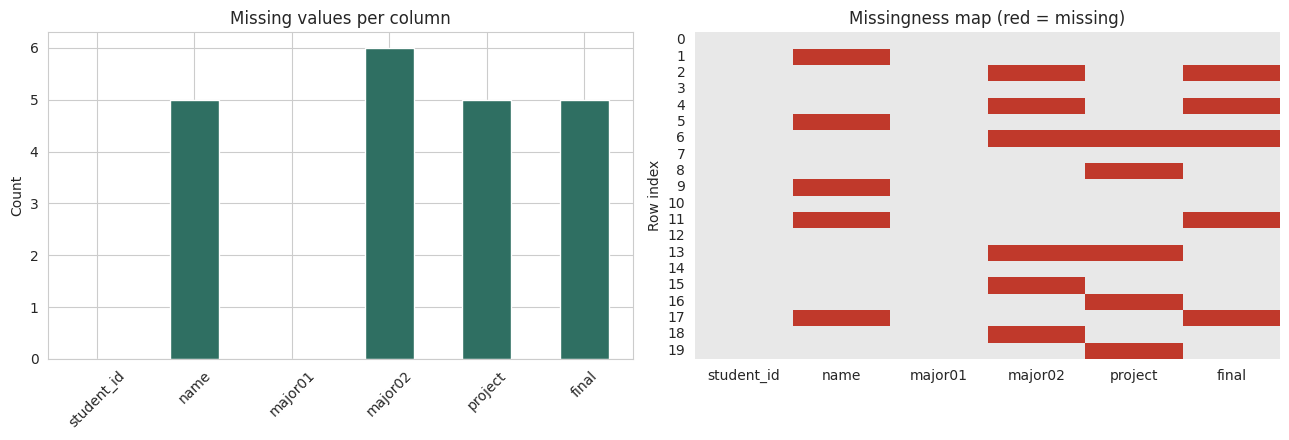

In [ ]:
# A picture is worth a thousand isnull() calls — where exactly are the gaps?

#fig — the overall figure (the whole canvas both charts live on).
#axes — an array of the individual subplot areas. Since we have 2 subplots, axes is an array of length 2: axes[0] is the left slot, axes[1] is the right slot.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# 13 by 4.5 - length by width
# summary has two columns, so we retrieve missing count
# axes[0] means first column in the figure
# rotation defines the orientation of the labels on the x-axis

summary["missing_count"] .plot(kind="bar", ax=axes[0], color="#2f6f62")
axes[0].set_title("Missing values per column")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=45)

# Passes missing value in the dataframe
# cmap -> color map -> specifies color scheme
# cbar -> color bar -> controls whether a scale/legend explaining what the heatmap colors mean is displayed
# 1 - indicates missing values
# 0 - indicates non-missing vals
# 0.5 - color scale transition
# the legend is simply a color scale distinguishing 1 (missing) vs 0 (non-missing)
# fractional values are transitions from 0 - 1
sns.heatmap(df.isnull(),  cbar=False, cmap=["#e8e8e8","#c0392b"], ax=axes[1])
axes[1].set_title("Missingness map (red = missing)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Row index")

plt.tight_layout() # adjusts the format of the plots - spaces out the plots so that elements like titles, axis points, x-ticks dont overlap or cutoff
plt.show() # renders/shows final visualization

**Reading the damage report:**

- `major01` has **zero** missing values — every student has a first-major score.
- `name`, `major02`, `project`, and `final` all have gaps, ranging from a handful of rows to
  nearly a third of the class.

Before deciding what to do, it's worth asking *why* a value might be missing:

| Pattern | Meaning | Example here |
|---|---|---|
| **MCAR** — Missing Completely at Random | The gap has nothing to do with any value, observed or not | A sync glitch dropped a random cell |
| **MAR** — Missing at Random | The chance of missing depends on *other observed* data | Late-registering students are missing `major01` because they hadn't taken it yet |
| **MNAR** — Missing Not at Random | The chance of missing depends on the *missing value itself* | A student who failed the `final` skipped submitting it out of embarrassment |

You can't always tell which case you're in from the data alone — but the distinction shapes
whether dropping or filling is defensible. Blindly filling MNAR data with the mean can hide
exactly the students who most need attention.

## 🧭 Step 3 — Pick a strategy, column by column

There is no single "correct" way to handle missing data — the right move depends on **what
the column means** and **how much is missing**. Here's the call you're going to make for this
gradebook:

| Column | % missing | Strategy | Why |
|---|---|---|---|
| `name` | small | **Drop those rows** | You cannot report a grade for a student you cannot identify — no value can substitute for an identity |
| `major01` | 0% | **Nothing to do** | Complete already |
| `major02` | moderate | **Fill with the column mean** | A continuous score close to normally distributed; mean imputation preserves the class average for downstream stats |
| `project` | moderate | **Fill with the column median** | Project scores are more skewed (a few 0s from late submissions) — median resists those outliers better than the mean |
| `final` | small–moderate | **Drop those rows** | The final exam is the single highest-stakes score — guessing it for a registrar submission is not defensible |

This mirrors the three big levers you have for any dataset:

1. **Drop** — safest when missingness is small and the value can't be reasonably guessed
2. **Fill with a constant / statistic** — good for continuous data where a placeholder is
   defensible and you need to keep every row
3. **Forward/backward fill** — best for ordered or time-series data, which we'll demo separately below

Let's apply each technique — starting with the building blocks, then the final pipeline.

## ✂️ Strategy A — Dropping missing values with `dropna()`

`dropna()` removes rows (or columns) that contain missing values. The key arguments:

- `axis=0` (default) drops **rows**; `axis=1` drops **columns**
- `subset=[...]` only looks at the listed columns when deciding what counts as "missing"
- `how="any"` (default) drops a row if *any* listed column is missing; `how="all"` requires *every* column to be missing
- `thresh=N` keeps a row only if it has at least `N` non-missing values

Let's see the blunt version first — dropping any row with *any* missing value anywhere —
and see how much of the class it costs you.

In [ ]:
before = len(df) # saves initial number of rows/cols
df_drop_any = df.dropna()
after = len(df_drop_any) # new dataset after dropping

print(f"Rows before: {before}") # 20 rows
print(f"Rows after dropping ANY missing value: {after}") # 6 rows
print(f"Students lost: {before - after}  ({(before - after) / before:.0%} of the class!)")

Rows before: 20
Rows after dropping ANY missing value: 6
Students lost: 14  (70% of the class!)


Ouch — dropping on *any* missing value throws away a large chunk of a class that's
otherwise fine. That's the trap of the blunt approach: it punishes every column's gaps
equally, even the ones you don't actually care about right now.

This is exactly why Step 3's per-column plan matters. Let's use `subset` to drop rows only
where it's truly non-negotiable — missing `name` or missing `final`.

In [ ]:
df_step = df.dropna(subset=["name", "final"]) # drops missing values from specific columns

print(f"Rows before: {len(df)}")
print(f"Rows after dropping only missing name/final: {len(df_step)}")
print(f"Students lost: {len(df) - len(df_step)}") # before - after
df_step

Rows before: 20
Rows after dropping only missing name/final: 12
Students lost: 8


,student_id,name,major01,major02,project,final
0,900000001,Student 05,15.25,14.00,18.00,17.000000
3,900000004,Student 02,5.91,1.25,5.00,7.000000
7,900000008,Student 12,16.00,12.63,16.67,15.333333
8,900000009,Student 07,10.00,6.38,NaN,8.000000
10,900000011,Student 01,10.56,12.00,11.33,13.300000
12,900000013,Student 08,20.00,18.88,18.67,18.500000
13,900000014,Student 15,10.00,NaN,NaN,3.000000
14,900000015,Student 04,14.75,11.90,13.40,14.000000
15,900000016,Student 09,17.20,NaN,15.90,16.800000
16,900000017,Student 13,12.10,8.75,NaN,10.500000


Much better — you only lose students for reasons you can defend to the Registrar. Note
`thresh` as a middle ground you'll meet in real datasets: `df.dropna(thresh=4)` would keep any
row that has **at least 4** non-missing values out of 6 columns, regardless of *which* ones.

In [ ]:
# thresh in action: keep rows with at least 4 non-null values (out of 6 columns)
df.dropna(thresh=4).shape # at least 4 missing values should be present in order for the values to be dropped

(19, 6)

## 🧱 Strategy B — Filling with a constant using `fillna()`

Sometimes a missing value has an obvious real-world meaning. Imagine a `late_penalty` column
where a blank simply means "no penalty was applied" — filling with `0` is not a guess, it's
recovering the true value. `fillna()` takes the replacement value directly:

```python
df["column"].fillna(0, inplace=True)
```

We don't have a natural "blank = zero" column in this gradebook (guessing `0` for a missing
exam score would be a serious accusation against a student!), so let's demonstrate the
mechanic on a safe copy before moving to the statistical fills we'll actually use.

In [ ]:
demo = df[["name", "project"]].copy()
print("Before:")
display(demo.head(15))

demo["project"] = demo["project"].fillna(0)
print("\nAfter filling with a constant (0):")
display(demo.head(15))

Before:


,name,project
0,Student 05,18.000
1,NaN,14.670
2,Student 06,16.250
3,Student 02,5.000
4,Student 11,6.670
5,NaN,15.758
6,Student 03,NaN
7,Student 12,16.670
8,Student 07,NaN
9,NaN,11.670



After filling with a constant (0):


,name,project
0,Student 05,18.000
1,NaN,14.670
2,Student 06,16.250
3,Student 02,5.000
4,Student 11,6.670
5,NaN,15.758
6,Student 03,0.000
7,Student 12,16.670
8,Student 07,0.000
9,NaN,11.670


Notice the pattern: `fillna()` returns a **new** Series/DataFrame by default — we
reassigned it back to `demo["project"]`. You can also pass `inplace=True` to modify in place,
as the original slides do; both are valid, and `inplace=True` is being phased out in newer
pandas in favor of reassignment, so we'll use reassignment throughout this notebook.

## 📊 Strategy C — Imputing with the mean or median

For `major02` and `project`, dropping rows would cost you real students over a handful of
gaps, and guessing `0` would tank their average unfairly. A better placeholder is a
**summary statistic** of the column itself.

- **Mean** — good default for roughly symmetric data
- **Median** — more robust when the column has outliers or skew (like a few 0-scores from
  late submissions dragging the mean down)

Let's compare both before choosing.

major02 — mean: 11.2 | median: 11.95
project — mean: 13.69 | median: 14.67


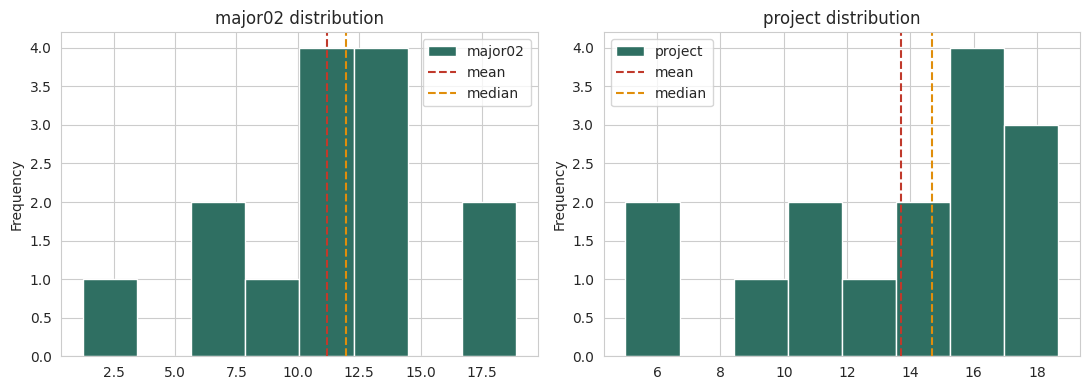

In [ ]:
print("major02 — mean:", round(df["major02"].mean(), 2), "| median:", round(df["major02"].median(), 2))
print("project — mean:", round(df["project"].mean(), 2), "| median:", round(df["project"].median(), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df["major02"].dropna().plot(kind="hist", bins=8, ax=axes[0], color="#2f6f62", edgecolor="white")
#NOTE that df["major02"].dropna()  is different from df["major02"]= df["major02"].dropna(). The first one does not overwrite df["major02"]
# Drops and plots

axes[0].axvline(df["major02"].mean(), color="#c0392b", linestyle="--", label="mean") # Vertical line displayed
axes[0].axvline(df["major02"].median(), color="#e08e0b", linestyle="--", label="median")
axes[0].set_title("major02 distribution")
axes[0].legend()

df["project"].dropna().plot(kind="hist", bins=8, ax=axes[1], color="#2f6f62", edgecolor="white")
axes[1].axvline(df["project"].mean(), color="#c0392b", linestyle="--", label="mean")
axes[1].axvline(df["project"].median(), color="#e08e0b", linestyle="--", label="median")
axes[1].set_title("project distribution")
axes[1].legend()

plt.tight_layout()
plt.show()

`major02` looks fairly symmetric — mean and median are close, so either is defensible.
`project` is pulled down by a couple of low scores, so the median sits a bit higher than the
mean and better represents a "typical" student. This confirms the plan from Step 3: **mean for
`major02`, median for `project`**.

In [ ]:
df_step["major02"] = df_step["major02"].fillna(df_step["major02"].mean())
df_step["project"] = df_step["project"].fillna(df_step["project"].median())

df_step[["name", "major02", "project"]]

/tmp/ipykernel_447/3139225451.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_step["major02"] = df_step["major02"].fillna(df_step["major02"].mean())
/tmp/ipykernel_447/3139225451.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_step["project"] = df_step["project"].fillna(df_step["project"].median())


,name,major02,project
0,Student 05,14.00,18.00
3,Student 02,1.25,5.00
7,Student 12,12.63,16.67
8,Student 07,6.38,15.05
10,Student 01,12.00,11.33
12,Student 08,18.88,18.67
13,Student 15,10.96,15.05
14,Student 04,11.90,13.40
15,Student 09,10.96,15.90
16,Student 13,8.75,15.05


## ⏩ Strategy D — Forward/backward fill for ordered data

Mean and median imputation assume row order doesn't matter — reasonable for a gradebook,
where row 5 has no relationship to row 6. But some data *is* ordered: daily attendance,
sensor readings, stock prices. There, the most sensible guess for a gap is often "whatever
came right before (or after) it."

`ffill()` carries the last valid value **forward**; `bfill()` carries the next valid value
**backward**. Let's see it on a short attendance log for one section of CS316.

In [ ]:
attendance = pd.DataFrame({
    "week": [1, 2, 3, 4, 5, 6, 7, 8],
    "students_present": [42, 40, np.nan, np.nan, 39, np.nan, 41, 41],
}) # Forward and Backward fills are only applicable for sequential data
print("Original:")
display(attendance)

attendance["ffill"] = attendance["students_present"].ffill() # previous values used to replace null vals
attendance["bfill"] = attendance["students_present"].bfill() # next values are used to replace null vals
attendance

Original:


,week,students_present
0,1,42.0
1,2,40.0
2,3,NaN
3,4,NaN
4,5,39.0
5,6,NaN
6,7,41.0
7,8,41.0


,week,students_present,ffill,bfill
0,1,42.0,42.0,42.0
1,2,40.0,40.0,40.0
2,3,NaN,40.0,39.0
3,4,NaN,40.0,39.0
4,5,39.0,39.0,39.0
5,6,NaN,39.0,41.0
6,7,41.0,41.0,41.0
7,8,41.0,41.0,41.0


`ffill` assumes "attendance probably stayed about the same as last week" — a reasonable
assumption for a slow-moving weekly headcount. `bfill` looks the opposite direction. Either can
be right depending on what you know about *why* the gap exists — always ask that question
before reaching for either one.

## 🛠️ Step 4 — Assemble the full cleaning pipeline

Time to put it all together into one clean, repeatable pipeline you could hand to next
semester's TA. Starting fresh from the original damaged export:

In [ ]:
def clean_gradebook(raw: pd.DataFrame) -> pd.DataFrame:
    '''Clean the CS316 gradebook export following the Step 3 decision table.'''
    clean = raw.copy()

    # 1. Drop rows where identity or the final exam score is missing —
    #    no statistic can substitute for either.
    clean = clean.dropna(subset=["name", "final"]) # drop missing rows under specific columns

    # 2. Impute major02 with the column mean (roughly symmetric distribution).
    clean["major02"] = clean["major02"].fillna(clean["major02"].mean())

    # 3. Impute project with the column median (skewed by a few low scores).
    clean["project"] = clean["project"].fillna(clean["project"].median())

    return clean.reset_index(drop=True) # df.reset_index - updated / new index after dropping


clean_df = clean_gradebook(df) # invokes the method and passes the parameter, that is returned as a df with new index
clean_df

,student_id,name,major01,major02,project,final
0,900000001,Student 05,15.25,14.00,18.00,17.000000
1,900000004,Student 02,5.91,1.25,5.00,7.000000
2,900000008,Student 12,16.00,12.63,16.67,15.333333
3,900000009,Student 07,10.00,6.38,15.05,8.000000
4,900000011,Student 01,10.56,12.00,11.33,13.300000
5,900000013,Student 08,20.00,18.88,18.67,18.500000
6,900000014,Student 15,10.00,10.96,15.05,3.000000
7,900000015,Student 04,14.75,11.90,13.40,14.000000
8,900000016,Student 09,17.20,10.96,15.90,16.800000
9,900000017,Student 13,12.10,8.75,15.05,10.500000


`clean.reset_index(drop=True)`

This line resets the DataFrame's row index back to a clean 0, 1, 2, 3, ... sequence, and drop=True means don't keep the old index around as a new column.

Why this is needed here:

In the clean_gradebook function, the very first cleaning step is:


`clean = clean.dropna(subset=["name", "final"])`

When dropna() removes rows, it doesn't renumber what's left — it just deletes those rows and leaves the original index values behind. So if, say, rows 2, 6, and 11 were dropped (because they were missing name or final), your resulting DataFrame would have an index that jumps around like:

0, 1, 3, 4, 5, 7, 8, 9, 10, 12, 13, ...

That's not necessarily broken, but it's awkward to work with — e.g., `clean.loc[2]` would raise a KeyError because row 2 no longer exists, and later operations that assume a tidy sequential index (like .iloc[], or just displaying/iterating rows) can behave unexpectedly.
What reset_index(drop=True) does:


`clean.reset_index(drop=True)`

It renumbers the remaining rows cleanly from 0 upward:

0, 1, 2, 3, 4, 5, 6, 7, 8, ...

Why `drop=True` specifically:
By default, `reset_index()` would take the old index and insert it as a new column (called "index") so you don't lose that information. `drop=True` says "no, just throw the old index away — I don't need to keep track of which original row number each row used to be."

In [ ]:
# Verify: zero missing values anywhere in the cleaned gradebook
remaining = clean_df.isnull().sum().sum()
print(f"Remaining missing values: {remaining}")
assert remaining == 0, "Still missing data — check the pipeline!"
print("✅ Gradebook is clean. Ready for submission.")

Remaining missing values: 0
✅ Gradebook is clean. Ready for submission.


`assert <condition>, <message>`
This is Python's built-in assert statement. It works like this:

If `<condition>` is True → nothing happens, code just continues to the next line.
If `<condition>` is False → Python immediately raises an AssertionError and stops execution, printing `<message>` so you know why it failed.

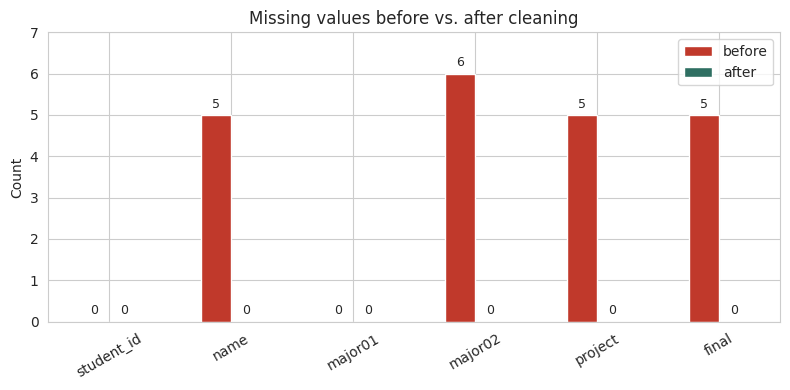

Students in original export: 20
Students in cleaned gradebook: 12
Class average (final): 12.6 / 20


In [ ]:
# Before vs. after, side by side
comparison = pd.DataFrame({
    "before": df.isnull().sum(),
    "after": clean_df.reindex(columns=df.columns).isnull().sum(),   #Rearrange clean_df's columns to match df's column order exactly
})
ax = comparison.plot(kind="bar", figsize=(8, 4), color=["#c0392b", "#2f6f62"])
plt.title("Missing values before vs. after cleaning")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.ylim(0, comparison["before"].max() + 1)  # headroom so 0-height "after" labels aren't clipped

# "after" bars are all 0 (that's the point!) so they're invisible by default —
# label every bar explicitly so the zeros actually show up as zeros, not gaps.
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9)

plt.tight_layout()
plt.show()

print(f"Students in original export: {len(df)}")
print(f"Students in cleaned gradebook: {len(clean_df)}")
print(f"Class average (final): {clean_df['final'].mean():.1f} / 20")

**4:53 PM.** Nine minutes to spare. You export `clean_df` to CSV and send it back to the instructor with a one-line note explaining exactly what you dropped, what you filled, and why —
because "I cleaned it" is never as convincing as "I dropped 2 rows missing identity/final
scores and imputed major02/project using mean/median, here's the before/after." That note is
the difference between a TA who got lucky and one who can be trusted with the gradebook again
next semester.

## 🎯 Your turn — practice exercises

The instructor was impressed and just forwarded you the gradebook for **Section B**. Use the
techniques above to handle it yourself. Work in the empty cells below; solutions are in the
final section if you get stuck — try each exercise first before peeking.

In [ ]:
import pandas as pd
section_b = pd.DataFrame({
    "student_id": [301, 302, 303, 304, 305, 306, 307, 308],
    "name": ["Huda Salem", "Karim Fathy", np.nan, "Dana Naji", "Sami Wael",
              "Reem Odeh", np.nan, "Bilal Nasser"],
    "quiz_avg": [8.5, np.nan, 7.2, 9.0, np.nan, 6.8, 8.1, np.nan],
    "midterm": [15.0, 12.5, np.nan, 17.0, 14.0, np.nan, 16.5, 13.0],
    "final": [np.nan, 18.0, 15.5, np.nan, 16.0, 14.5, 17.5, 12.0],
})
section_b

,student_id,name,quiz_avg,midterm,final
0,301,Huda Salem,8.5,15.0,NaN
1,302,Karim Fathy,NaN,12.5,18.0
2,303,NaN,7.2,NaN,15.5
3,304,Dana Naji,9.0,17.0,NaN
4,305,Sami Wael,NaN,14.0,16.0
5,306,Reem Odeh,6.8,NaN,14.5
6,307,NaN,8.1,16.5,17.5
7,308,Bilal Nasser,NaN,13.0,12.0


**Exercise 1.** How many missing values does each column in `section_b` have? Which
column is most affected?

**Exercise 2.** Following the same logic as Step 3, `name` should be dropped if missing (no
statistic replaces an identity) but `final` should this time be **filled with the median**
instead of dropped — assume the instructor has verbally confirmed those three scores separately
and just needs the sheet completed. Write the code for both steps.

**Exercise 3.** Fill `quiz_avg` with the column mean and `midterm` with the column median.
Confirm the result has zero missing values.

**Exercise 4 (stretch).** `section_b` is small enough that dropping *any* row with a missing
value would only cost you a couple of students. Compute how many rows `section_b.dropna()`
would keep, and write one sentence arguing whether that blunt approach is defensible here
compared to the targeted approach in Exercises 2–3.

In [ ]:
# Exercise 1 — your code here
section_b.isnull().sum() # asks about each column - NOT the entire dataset
# from the output, it can be deduced that quiz_avg assessment component is heavily affected by missing values
section_b


,student_id,name,quiz_avg,midterm,final
0,301,Huda Salem,8.5,15.0,NaN
1,302,Karim Fathy,NaN,12.5,18.0
2,303,NaN,7.2,NaN,15.5
3,304,Dana Naji,9.0,17.0,NaN
4,305,Sami Wael,NaN,14.0,16.0
5,306,Reem Odeh,6.8,NaN,14.5
6,307,NaN,8.1,16.5,17.5
7,308,Bilal Nasser,NaN,13.0,12.0


In [ ]:
# Exercise 2 — your code here

clean_ver= section_b.dropna(subset=['name']).copy() # saves changes to a new variable that serves as a backup copy-.copy() is used for best practice as its risky to directly modify original dataset in rl
clean_ver['final']=clean_ver['final'].fillna(clean_ver['final'].median())
clean_ver= clean_ver.reset_index(drop=True) # returns a new dataframe without updating original clean_ver
clean_ver


,student_id,name,quiz_avg,midterm,final
0,301,Huda Salem,8.5,15.0,NaN
1,302,Karim Fathy,NaN,12.5,18.0
2,303,NaN,7.2,NaN,15.5
3,304,Dana Naji,9.0,17.0,NaN
4,305,Sami Wael,NaN,14.0,16.0
5,306,Reem Odeh,6.8,NaN,14.5
6,307,NaN,8.1,16.5,17.5
7,308,Bilal Nasser,NaN,13.0,12.0


In [ ]:
# Exercise 3 — your code here

# Fill quiz_avg w/ column mean
clean_ver['quiz_avg']= clean_ver['quiz_avg'].fillna(clean_ver['quiz_avg'].mean())
clean_ver['midterm']=clean_ver['midterm'].fillna(clean_ver['midterm'].median())

# Confirm result has two missing values in total
clean_ver.isnull().sum().sum()

np.int64(0)

In [ ]:
# Exercise 4 — your code here
len(section_b.dropna())


0

### ✅ Solutions

Expand only after attempting the exercises above.

In [ ]:
# Exercise 1
print(section_b.isnull().sum())
print("\nMost affected: 'quiz_avg' with 3 missing values out of 8 students",
      "(name and midterm each have 2, final has 2).")

student_id    0
name          2
quiz_avg      3
midterm       2
final         2
dtype: int64

Most affected: 'quiz_avg' with 3 missing values out of 8 students (name and midterm each have 2, final has 2).


In [ ]:
# Exercise 2
sb_clean = section_b.dropna(subset=["name"]).copy()
sb_clean["final"] = sb_clean["final"].fillna(sb_clean["final"].median())
sb_clean

,student_id,name,quiz_avg,midterm,final
0,301,Huda Salem,8.5,15.0,15.25
1,302,Karim Fathy,NaN,12.5,18.00
3,304,Dana Naji,9.0,17.0,15.25
4,305,Sami Wael,NaN,14.0,16.00
5,306,Reem Odeh,6.8,NaN,14.50
7,308,Bilal Nasser,NaN,13.0,12.00


In [ ]:
# Exercise 3
sb_clean["quiz_avg"] = sb_clean["quiz_avg"].fillna(sb_clean["quiz_avg"].mean())
sb_clean["midterm"] = sb_clean["midterm"].fillna(sb_clean["midterm"].median())

print("Remaining missing values:", sb_clean.isnull().sum().sum())
sb_clean

Remaining missing values: 0


,student_id,name,quiz_avg,midterm,final
0,301,Huda Salem,8.5,15.0,15.25
1,302,Karim Fathy,8.1,12.5,18.00
3,304,Dana Naji,9.0,17.0,15.25
4,305,Sami Wael,8.1,14.0,16.00
5,306,Reem Odeh,6.8,14.0,14.50
7,308,Bilal Nasser,8.1,13.0,12.00


In [ ]:
# Exercise 4
kept = len(section_b.dropna())
print(f"section_b.dropna() keeps {kept} of {len(section_b)} students.")
print(
    "Dropping any row with a missing value keeps ZERO students here — every single row "
    "has a gap somewhere. The blunt approach isn't just costly, it's unusable on this "
    "section. Most of those gaps (quiz_avg, midterm) are easily and defensibly imputed, "
    "and 'name' is the only column worth dropping rows over — so the targeted approach "
    "from Exercises 2-3 is not just preferable but necessary here."
)

# results in 0 students records implying that each entry has at least one gap/missing value - this blunt approach is not only risky but it destroys the entire dataset rather than preparing them for processing.
# Alternatively, most of these gaps can be secured through imputation, and the 'name' is the only field worth eliminating rows thus the targeted approach where we decide on how to handle data based on the nature of each column and the proportion of data missing
# is the most effective here

section_b.dropna() keeps 0 of 8 students.
Dropping any row with a missing value keeps ZERO students here — every single row has a gap somewhere. The blunt approach isn't just costly, it's unusable on this section. Most of those gaps (quiz_avg, midterm) are easily and defensibly imputed, and 'name' is the only column worth dropping rows over — so the targeted approach from Exercises 2-3 is not just preferable but necessary here.


## 📋 Cheat sheet

| Task | Code | Notes |
|---|---|---|
| Flag missing cells | `df.isnull()` / `df.isna()` | Same-shaped boolean DataFrame |
| Count missing per column | `df.isnull().sum()` | `True` counts as 1 |
| % missing per column | `df.isnull().mean() * 100` | Easier to compare across columns of different sizes |
| Drop rows with any missing | `df.dropna()` | Blunt — can lose a lot of data |
| Drop rows missing specific columns | `df.dropna(subset=["col1", "col2"])` | Targeted — usually the better default |
| Drop rows below a completeness threshold | `df.dropna(thresh=N)` | Keeps rows with at least `N` non-null values |
| Drop columns instead of rows | `df.dropna(axis=1)` | Use when a whole column is unreliable |
| Fill with a constant | `df["col"].fillna(0)` | Only when the blank has a real, known meaning |
| Fill with the mean | `df["col"].fillna(df["col"].mean())` | Good default for symmetric numeric data |
| Fill with the median | `df["col"].fillna(df["col"].median())` | More robust to outliers/skew |
| Carry the previous value forward | `df["col"].ffill()` | Ordered/time-series data |
| Carry the next value backward | `df["col"].bfill()` | Ordered/time-series data |

**The one question to ask before any of the above:** *would a human who knows this domain
consider my chosen fill a reasonable guess — or am I quietly inventing data?*
---
*CS316 — Introduction to Data Science · Missing Data lab notebook*